In [1]:
import sys
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sys.path.append(str(Path().resolve().parent/"src"))
from features import add_geometry_features

results = {}

In [2]:
# helpers
def evaluate(y_true,y_pred):
    mae = mean_absolute_error(y_true,y_pred)
    rmse = root_mean_squared_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)
    return mae, rmse, r2

# Mean Baseline
Taking the mean of both the cl and cd and using that as the prediction

In [3]:
# Load the CSV data into dataframe
CSV_PATH = Path().resolve().parent/"data"/"processed"/"airfrans_coefficients.csv"
df = pd.read_csv(CSV_PATH)


# Split dataframe into train and test data
train_df = df.loc[df["split_full"]=="train"]
test_df = df.loc[df["split_full"]=="test"]

# Get mean cl and cd value from training data
mean_cl = train_df["cl"].mean()
mean_cd = train_df["cd"].mean()

print(f"Mean cl from training data: {mean_cl}")
print(f"Mean cd from training data: {mean_cd}")

# Predict the values by solely taking the mean
cl_pred = np.full(len(test_df),mean_cl)
cd_pred = np.full(len(test_df),mean_cd)

# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_pred)

# Outputs
print("\n--- Cl (coefficient of Lift) ---")
print(f"MAE: {cl_mae}")
print(f"RMSE: {cl_rmse}")
print(f"R^2: {cl_r2}")

print("--- Cd (coefficient of Drag) ---")
print(f"MAE: {cd_mae}")
print(f"RMSE: {cd_rmse}")
print(f"R^2: {cd_r2}")

# add to the results
results["mean_baseline"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

Mean cl from training data: 0.6767168151116846
Mean cd from training data: 0.012495524718604436

--- Cl (coefficient of Lift) ---
MAE: 0.4982478689429241
RMSE: 0.579817991426866
R^2: -0.0020055116225636826
--- Cd (coefficient of Drag) ---
MAE: 0.0034340043936832883
RMSE: 0.004728631989820384
R^2: -0.0011017976425085063


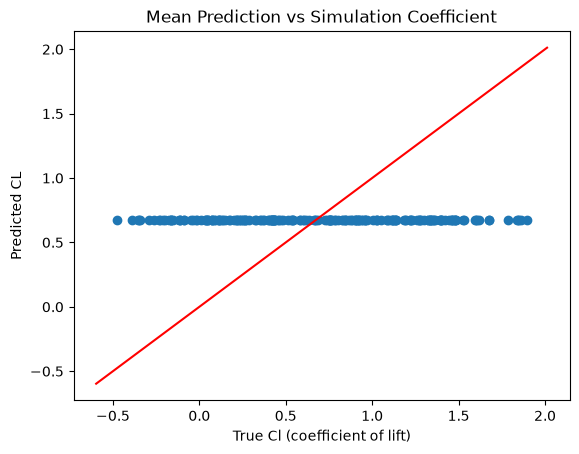

In [4]:
# Visualisation of the pred cl vs true
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cl"],cl_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted CL")
ax.set_xlabel("True Cl (coefficient of lift)")
plt.show()

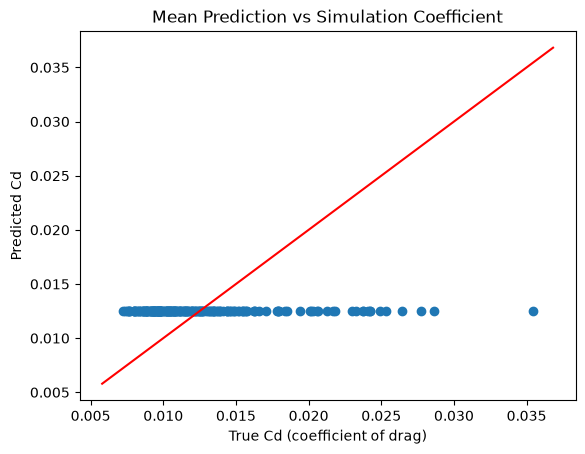

In [5]:
# Visualisation of the pred cd vs true
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cd"],cd_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted Cd")
ax.set_xlabel("True Cd (coefficient of drag)")
plt.show()

In [6]:
print(results)

{'mean_baseline': {'cl_mae': 0.4982478689429241, 'cl_rmse': 0.579817991426866, 'cl_r2': -0.0020055116225636826, 'cd_mae': 0.0034340043936832883, 'cd_rmse': 0.004728631989820384, 'cd_r2': -0.0011017976425085063}}


# Thin-Airfoil Theory

$Cl = 2\pi \times (\alpha-\alpha_{lo})$

Assumptions:
- The airfoil is very thin: airfoil is treated as just its camber line
- The angle of attack is small
- the air has no viscosity
- The flow leaves the sharp trailing edge smoothly


In [7]:
cl_pred = 2*np.pi * np.deg2rad(test_df["angleOfAttack"])

cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_pred)

print("\n--- Cl (coefficient of Lift) ---")
print(f"MAE: {cl_mae}")
print(f"RMSE: {cl_rmse}")
print(f"R^2: {cl_r2}")

results["thin_airfoil_theory"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2}


--- Cl (coefficient of Lift) ---
MAE: 0.21423209633326046
RMSE: 0.29375180477444884
R^2: 0.7428137043370256


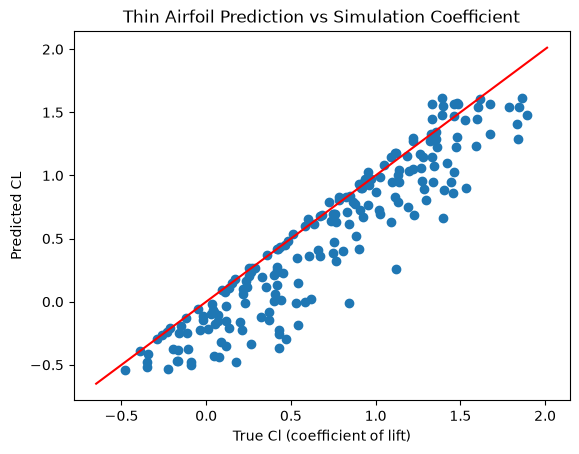

In [8]:
# Visualisation of thin-Airfoil Theory
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cl"],cl_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Thin Airfoil Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted CL")
ax.set_xlabel("True Cl (coefficient of lift)")
plt.show()

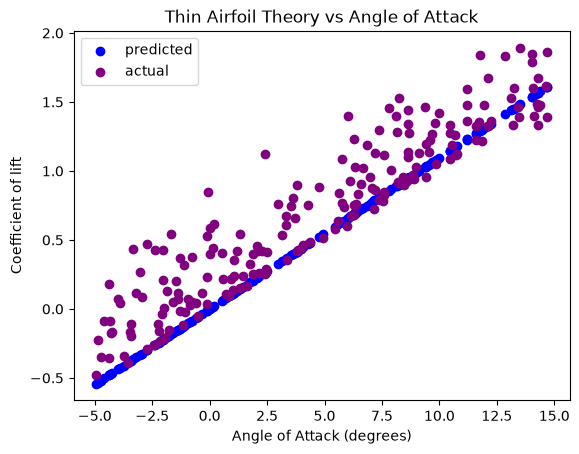

In [9]:
# visualisation of thin-airfoil theory against angle of attack
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["angleOfAttack"],cl_pred, c="Blue", label="predicted")
ax.scatter(test_df["angleOfAttack"],test_df["cl"],c="Purple", label="actual")

# plot y=x as ideal line
# lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
#ax.plot(lims, lims,c="red")

ax.set_title("Thin Airfoil Theory vs Angle of Attack")
ax.set_ylabel("Coefficient of lift")
ax.set_xlabel("Angle of Attack (degrees)")
ax.legend()
plt.show()

# Linear Regression
In order for linear regression to make use of as much information as possible, the 4 and 5 digit values need to be converted into a universal values:
- `max_camber` = m/100 or calculated from camber line
- `camber_pos` = p/10 or calculated from camber line
- `thickness` = XX/100 for both
- `reflex` = 0 or q as 0 or 1

In [10]:
# Use camber_line function to get max camber and position

import airfrans as af
from airfrans.naca_generator import camber_line
DATA_PATH = Path().resolve().parent/"data"/"Dataset"

sim = df.iloc[0]
simulation = af.Simulation(DATA_PATH,sim["name"])

rang = np.linspace(0,1,1001)
range_line = camber_line([sim["L"],sim["P"],sim["Q"]],rang)
range_max_camber = np.max(range_line[0])
range_position = rang[np.argmax(range_line[0])]

print(f"Range: {range_max_camber} {range_position}")

Range: 0.04580895799385703 0.271


Used Above cell to build `add_geometry_features()` in `src/features.py`

In [11]:
# Add the geometric features to the dataframe
df = add_geometry_features(df)
df.describe()

# Show Correlations between the 4 variables and CL
print("--- Correlations to Cl ---")
print(f"angleOfAttack = {df['cl'].corr(df['angleOfAttack'])}")
print(f"Re = {df['cl'].corr(df['Re'])}")
print(f"max_camber ={df['cl'].corr(df['max_camber'])}")
print(f"camber_pos ={df['cl'].corr(df['camber_pos'])}")
print(f"thickness ={df['cl'].corr(df['thickness'])}")
print(f"reflex ={df['cl'].corr(df['reflex'])}")

# Show Correlations between the 4 variables and CD 
print("--- Correlations to Cd ---")
print(f"angleOfAttack = {df['cd'].corr(df['angleOfAttack'])}")
print(f"Re = {df['cd'].corr(df['Re'])}")
print(f"max_camber ={df['cd'].corr(df['max_camber'])}")
print(f"camber_pos ={df['cd'].corr(df['camber_pos'])}")
print(f"thickness ={df['cd'].corr(df['thickness'])}")
print(f"reflex ={df['cd'].corr(df['reflex'])}")

--- Correlations to Cl ---
angleOfAttack = 0.9421149874539194
Re = 0.031089254680034394
max_camber =0.22262959249873193
camber_pos =0.1223980957966654
thickness =-0.0745838743991554
reflex =-0.03266671244301766
--- Correlations to Cd ---
angleOfAttack = 0.7578030966681518
Re = -0.14602525510919803
max_camber =0.1527652136548673
camber_pos =0.0379715978461967
thickness =0.0400881776656811
reflex =-0.04736244293786302


In [12]:
# Now we have constant features for all airfoil, we can now implement linear regression

# Adding Re_millions column to fix large difference in scales affecting model performance
df["Re_millions"] = df["Re"]/1e6

# Split new dataframe into train and test data
train_df = df.loc[df["split_full"]=="train"]
test_df = df.loc[df["split_full"]=="test"]

FEATURES = ["angleOfAttack","Re_millions","max_camber", "camber_pos", "thickness", "reflex"]

# Create X datasets
x_train = train_df[FEATURES]
x_test = test_df[FEATURES]

# Create Y datasets
y_train = train_df[["cl","cd"]]
y_test = test_df[["cl","cd"]]


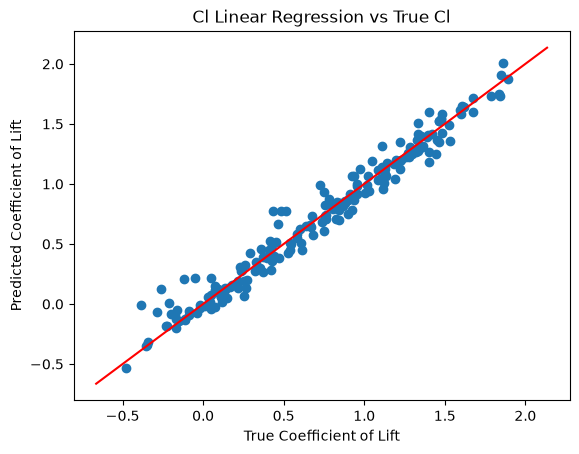

angleOfAttack    0.099549
Re_millions      0.006241
max_camber       7.301207
camber_pos       0.587344
thickness       -0.549463
reflex           0.013301
dtype: float64
intercept: -0.1109135178705245


In [13]:
# Build Cl linear Regression model

cl_model = LinearRegression()
cl_model.fit(x_train, y_train["cl"])
cl_y_pred = cl_model.predict(x_test)

# Plot graph of it
fig, ax = plt.subplots()
ax.scatter(y_test["cl"],cl_y_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Cl Linear Regression vs True Cl")
ax.set_ylabel("Predicted Coefficient of Lift")
ax.set_xlabel("True Coefficient of Lift")
plt.show()

# print Coefficients
coefs = pd.Series(cl_model.coef_, index=cl_model.feature_names_in_)
print(coefs)
print("intercept:", cl_model.intercept_)

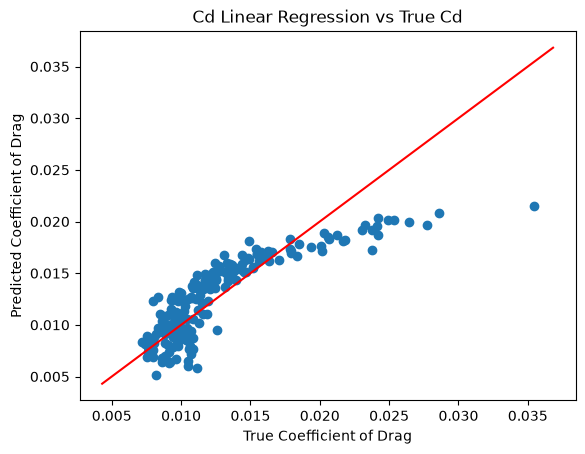

angleOfAttack    0.000694
Re_millions     -0.000712
max_camber       0.039790
camber_pos       0.002289
thickness        0.007831
reflex          -0.000330
dtype: float64
intercept: 0.009532450566809047


In [14]:
# Build Cd linear Regression model

cd_model = LinearRegression()
cd_model.fit(x_train, y_train["cd"])
cd_y_pred = cd_model.predict(x_test)

# Plot graph of it
fig, ax = plt.subplots()
ax.scatter(y_test["cd"],cd_y_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Cd Linear Regression vs True Cd")
ax.set_ylabel("Predicted Coefficient of Drag")
ax.set_xlabel("True Coefficient of Drag")
plt.show()

# print Coefficients
coefs = pd.Series(cd_model.coef_, index=cd_model.feature_names_in_)
print(coefs)
print("intercept:", cd_model.intercept_)

In [15]:
## Add results to table
# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_y_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_y_pred)

# add to the results
results["linear_regression"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

print(pd.DataFrame(results))

         mean_baseline  thin_airfoil_theory  linear_regression
cl_mae        0.498248             0.214232           0.074324
cl_rmse       0.579818             0.293752           0.102960
cl_r2        -0.002006             0.742814           0.968405
cd_mae        0.003434                  NaN           0.001961
cd_rmse       0.004729                  NaN           0.002555
cd_r2        -0.001102                  NaN           0.707767


Due to the high correlation between angle of attack and CL and Cd, it introduces the question of how much is being added by the other features. Below explores this further

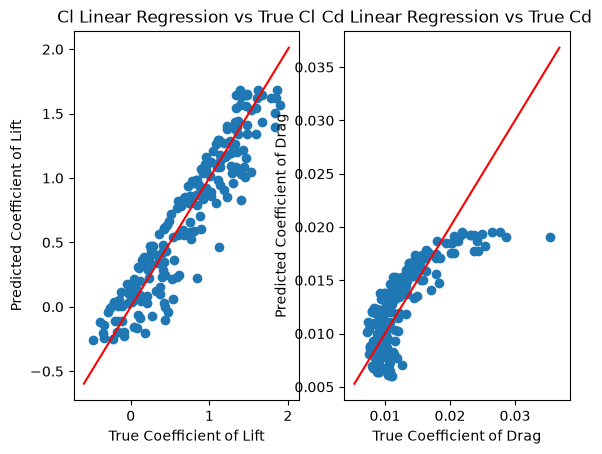

--- CL Model ---
angleOfAttack    0.099147
dtype: float64
intercept: 0.23033418409195544
--- CD Model ---
angleOfAttack    0.000691
dtype: float64
intercept: 0.009386139432994612


In [16]:
# Building linear regression models on only angle of attack
fig, ax = plt.subplots(1,2)

FEATURES = ["angleOfAttack"]

# Create X datasets
x_train = train_df[FEATURES]
x_test = test_df[FEATURES]

# Cl model
cl_aoa_model = LinearRegression()
cl_aoa_model.fit(x_train, y_train["cl"])
cl_y_pred = cl_aoa_model.predict(x_test)

# Cd model
cd_aoa_model = LinearRegression()
cd_aoa_model.fit(x_train, y_train["cd"])
cd_y_pred = cd_aoa_model.predict(x_test)

# Plot graphs of it
ax[0].scatter(y_test["cl"],cl_y_pred)
ax[1].scatter(y_test["cd"],cd_y_pred)

# plot y=x as ideal line
lims = [np.min([ax[0].get_xlim(),ax[0].get_ylim()]),np.max([ax[0].get_xlim(),ax[0].get_ylim()])]
ax[0].plot(lims, lims,c="red")
lims = [np.min([ax[1].get_xlim(),ax[1].get_ylim()]),np.max([ax[1].get_xlim(),ax[1].get_ylim()])]
ax[1].plot(lims, lims,c="red")

# Set titles
ax[0].set_title("Cl Linear Regression vs True Cl")
ax[0].set_ylabel("Predicted Coefficient of Lift")
ax[0].set_xlabel("True Coefficient of Lift")

ax[1].set_title("Cd Linear Regression vs True Cd")
ax[1].set_ylabel("Predicted Coefficient of Drag")
ax[1].set_xlabel("True Coefficient of Drag")

# Add results to table
# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_y_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_y_pred)

# add to the results
results["linear_regression (aoa)"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

plt.show()
# print Coefficients
print("--- CL Model ---")
coefs = pd.Series(cl_aoa_model.coef_, index=cl_aoa_model.feature_names_in_)
print(coefs)
print("intercept:", cl_aoa_model.intercept_)

print("--- CD Model ---")
coefs = pd.Series(cd_aoa_model.coef_, index=cd_aoa_model.feature_names_in_)
print(coefs)
print("intercept:", cd_aoa_model.intercept_)

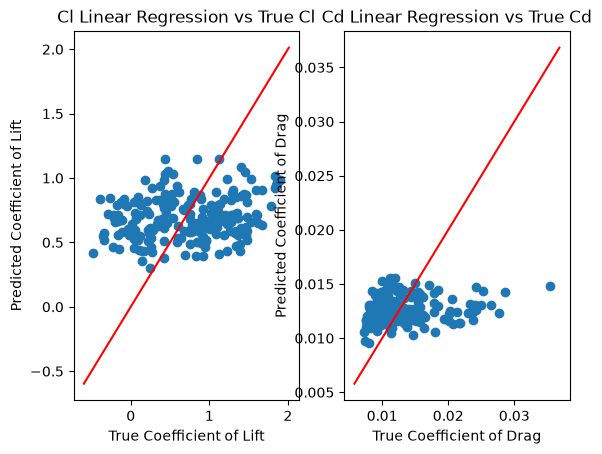

--- CL Model ---
Re_millions    0.014826
max_camber     7.896943
camber_pos     0.450576
thickness     -0.351203
reflex         0.038126
dtype: float64
intercept: 0.2948110695131477
--- CD Model ---
Re_millions   -0.000652
max_camber     0.043941
camber_pos     0.001336
thickness      0.009212
reflex        -0.000157
dtype: float64
intercept: 0.012359239473926588


In [17]:
# Building linear Regression models without Angle of Attack
fig, ax = plt.subplots(1,2)

FEATURES = ["Re_millions","max_camber", "camber_pos", "thickness", "reflex"]

# Create X datasets
x_train = train_df[FEATURES]
x_test = test_df[FEATURES]

# Cl model
cl_without_aoa_model = LinearRegression()
cl_without_aoa_model.fit(x_train, y_train["cl"])
cl_y_pred = cl_without_aoa_model.predict(x_test)

# Cd model
cd_without_aoa_model = LinearRegression()
cd_without_aoa_model.fit(x_train, y_train["cd"])
cd_y_pred = cd_without_aoa_model.predict(x_test)

# Plot graphs of it
ax[0].scatter(y_test["cl"],cl_y_pred)
ax[1].scatter(y_test["cd"],cd_y_pred)

# plot y=x as ideal line
lims = [np.min([ax[0].get_xlim(),ax[0].get_ylim()]),np.max([ax[0].get_xlim(),ax[0].get_ylim()])]
ax[0].plot(lims, lims,c="red")
lims = [np.min([ax[1].get_xlim(),ax[1].get_ylim()]),np.max([ax[1].get_xlim(),ax[1].get_ylim()])]
ax[1].plot(lims, lims,c="red")

# Set titles
ax[0].set_title("Cl Linear Regression vs True Cl")
ax[0].set_ylabel("Predicted Coefficient of Lift")
ax[0].set_xlabel("True Coefficient of Lift")

ax[1].set_title("Cd Linear Regression vs True Cd")
ax[1].set_ylabel("Predicted Coefficient of Drag")
ax[1].set_xlabel("True Coefficient of Drag")

# Add results to table
# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_y_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_y_pred)

# add to the results
results["linear_regression (without aoa)"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

plt.show()
# print Coefficients
print("--- CL Model ---")
coefs = pd.Series(cl_without_aoa_model.coef_, index=cl_without_aoa_model.feature_names_in_)
print(coefs)
print("intercept:", cl_without_aoa_model.intercept_)

print("--- CD Model ---")
coefs = pd.Series(cd_without_aoa_model.coef_, index=cd_without_aoa_model.feature_names_in_)
print(coefs)
print("intercept:", cd_without_aoa_model.intercept_)

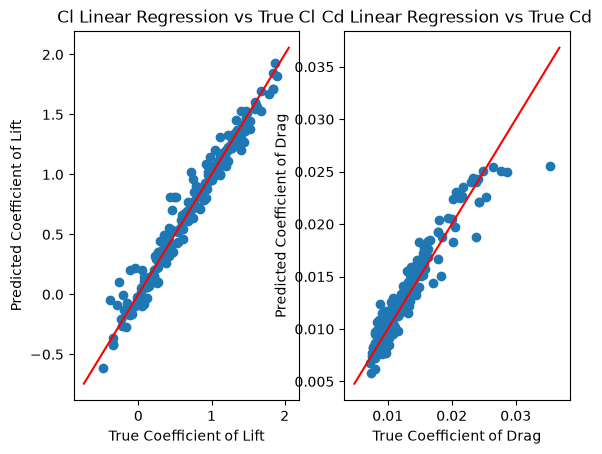

--- CL Model ---
angleOfAttack    0.110687
Re_millions      0.006334
max_camber       7.294614
camber_pos       0.580816
thickness       -0.606829
reflex           0.007963
aoa^2           -0.001159
dtype: float64
intercept: -0.09291600565143165
--- CD Model ---
angleOfAttack   -0.000072
Re_millions     -0.000718
max_camber       0.040243
camber_pos       0.002738
thickness        0.011775
reflex           0.000037
aoa^2            0.000080
dtype: float64
intercept: 0.008294841317862879


In [18]:
# Building linear Regression models with Angle of Attack squared as an additional feature
fig, ax = plt.subplots(1,2)

FEATURES = ["angleOfAttack","Re_millions","max_camber", "camber_pos", "thickness", "reflex",]

# Create X datasets
x_train = train_df[FEATURES]
x_test = test_df[FEATURES]

# Add aoa^2
x_train["aoa^2"] = x_train["angleOfAttack"] **2
x_test["aoa^2"] = x_test["angleOfAttack"] **2

# Cl model
cl_aoa2_model = LinearRegression()
cl_aoa2_model.fit(x_train, y_train["cl"])
cl_y_pred = cl_aoa2_model.predict(x_test)

# Cd model
cd_aoa2_model = LinearRegression()
cd_aoa2_model.fit(x_train, y_train["cd"])
cd_y_pred = cd_aoa2_model.predict(x_test)

# Plot graphs of it
ax[0].scatter(y_test["cl"],cl_y_pred)
ax[1].scatter(y_test["cd"],cd_y_pred)

# plot y=x as ideal line
lims = [np.min([ax[0].get_xlim(),ax[0].get_ylim()]),np.max([ax[0].get_xlim(),ax[0].get_ylim()])]
ax[0].plot(lims, lims,c="red")
lims = [np.min([ax[1].get_xlim(),ax[1].get_ylim()]),np.max([ax[1].get_xlim(),ax[1].get_ylim()])]
ax[1].plot(lims, lims,c="red")

# Set titles
ax[0].set_title("Cl Linear Regression vs True Cl")
ax[0].set_ylabel("Predicted Coefficient of Lift")
ax[0].set_xlabel("True Coefficient of Lift")

ax[1].set_title("Cd Linear Regression vs True Cd")
ax[1].set_ylabel("Predicted Coefficient of Drag")
ax[1].set_xlabel("True Coefficient of Drag")

# Add results to table
# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_y_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_y_pred)

# add to the results
results["linear_regression (aoa^2)"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

plt.show()
# print Coefficients
print("--- CL Model ---")
coefs = pd.Series(cl_aoa2_model.coef_, index=cl_aoa2_model.feature_names_in_)
print(coefs)
print("intercept:", cl_aoa2_model.intercept_)

print("--- CD Model ---")
coefs = pd.Series(cd_aoa2_model.coef_, index=cd_aoa2_model.feature_names_in_)
print(coefs)
print("intercept:", cd_aoa2_model.intercept_)

In [19]:
print(pd.DataFrame(results))

         mean_baseline  thin_airfoil_theory  linear_regression  \
cl_mae        0.498248             0.214232           0.074324   
cl_rmse       0.579818             0.293752           0.102960   
cl_r2        -0.002006             0.742814           0.968405   
cd_mae        0.003434                  NaN           0.001961   
cd_rmse       0.004729                  NaN           0.002555   
cd_r2        -0.001102                  NaN           0.707767   

         linear_regression (aoa)  linear_regression (without aoa)  \
cl_mae                  0.168153                         0.499262   
cl_rmse                 0.207557                         0.570719   
cl_r2                   0.871601                         0.029196   
cd_mae                  0.002301                         0.003492   
cd_rmse                 0.002956                         0.004662   
cd_r2                   0.608848                         0.026888   

         linear_regression (aoa^2)  
cl_mae          

# Findings
The overall findings are that the linear regression models score highly in the R^2 scores when including angle of Attack (AOA) and when excluding it perform fairly poorly. the mean_baseline and thin airfoil theory both dont perform spectacuarly for predicting a coefficient of lift compared to the linear Regression models. 


In terms of Features the finding is the coefficient of lift and drag have a large correlation with the AOA of ~0.94 and ~0.75 respectively. This resulted in around 87% of the results being explained by the angle, with the rest making up about 3%, together coming to an accuracy of around 97%. This prompted the exploration of further models that both include only AOA, exclude AOA and add AOA^2 as a feature. The results of these generally follow what was expected, only using the angle produces a relatively accuracte model due to the high correlation. without the angle does not produce a good model but this can be expected as you can't predict the lift giving just the shape of the airfoil without its angle. One very interesting take-back I have is with the Regression model with AOA^2, which scored very highly for the coefficient of drag, when compared to the other models, and this can be seen in the graph as well, where the relationship is far more linear between predicted and true Cd values. 

### Issues
We ran into an issue where due to the other features being floating point numbers and in contrast the Re value being in the millions, the model solvers were essentially ignoring the smaller values. therefore to remove this we created the new column `Re_millions` diving the number by 1000000 to align it better with the other features allowing the model coefficients to properly include it.